# Fase 1. Exploración inicial de los datos

In [35]:
import pandas as pd
import numpy as np
from IPython.display import display

ruta_csv = "datos/ventas.csv"

In [36]:
Ventas = pd.read_csv(ruta_csv)
display(Ventas.head(10))


,id_venta,fecha,producto,categoria,precio_unitario,cantidad,total_venta,metodo_pago,ciudad,edad_cliente,genero_cliente,canal_venta
0,1,2025-11-24,Laptop Gamer Asus ROG Strix,Laptop,29699.47,1,29699.47,Tarjeta de débito,Monterrey,65,Masculino,Aplicación móvil
1,2,2025-10-07,Dell XPS 13,Laptop,26293.09,1,26293.09,Efectivo,Puebla,32,Femenino,Tienda física
2,3,2025-10-15,Google Pixel 8,Smartphone,14085.72,2,28171.44,Tarjeta de crédito,Ciudad de México,66,Femenino,Aplicación móvil
3,4,2025-08-05,Lenovo Tab M10,Tablet,3669.08,2,7338.16,Efectivo,Guadalajara,42,Masculino,Página web
4,5,2025-11-06,iPad Air 5a Gen,Tablet,13809.11,1,13809.11,Transferencia,Guadalajara,53,Masculino,Aplicación móvil
5,6,2025-11-13,Nintendo Switch OLED,Gaming,6952.37,3,20857.11,Efectivo,Ciudad de México,60,Masculino,Página web
6,7,2025-02-10,Consola Xbox Series X,Gaming,12438.74,2,24877.48,Tarjeta de crédito,León,58,Femenino,Tienda física
7,8,2025-07-09,Samsung Galaxy Tab S9,Tablet,16271.26,1,16271.26,Tarjeta de débito,Toluca,64,Masculino,Página web
8,9,2025-07-14,Samsung Galaxy Tab S9,Tablet,16294.36,1,16294.36,Tarjeta de débito,Ciudad de México,69,Masculino,Página web
9,10,2025-02-03,Google Pixel 8,Smartphone,14734.44,2,29468.88,Tarjeta de débito,León,43,Femenino,Aplicación móvil


In [37]:
filas = len(Ventas.iloc[:, 0])
columnas = len(Ventas.columns)
print(f"Filas: {filas}, Columnas: {columnas}")



Filas: 1000, Columnas: 12


In [38]:
Tipo_de_datos = Ventas.dtypes
print(Tipo_de_datos)

id_venta             int64
fecha                  str
producto               str
categoria              str
precio_unitario    float64
cantidad             int64
total_venta        float64
metodo_pago            str
ciudad                 str
edad_cliente         int64
genero_cliente         str
canal_venta            str
dtype: object


In [39]:
datos_nulos = Ventas.isnull().sum()
print(datos_nulos)

id_venta           0
fecha              0
producto           0
categoria          0
precio_unitario    0
cantidad           0
total_venta        0
metodo_pago        0
ciudad             0
edad_cliente       0
genero_cliente     0
canal_venta        0
dtype: int64


In [40]:
Datos_duplicados =Ventas[Ventas.duplicated(keep=False)]  
print(Datos_duplicados)

Empty DataFrame
Columns: [id_venta, fecha, producto, categoria, precio_unitario, cantidad, total_venta, metodo_pago, ciudad, edad_cliente, genero_cliente, canal_venta]
Index: []


In [41]:
Detalles = Ventas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_venta         1000 non-null   int64  
 1   fecha            1000 non-null   str    
 2   producto         1000 non-null   str    
 3   categoria        1000 non-null   str    
 4   precio_unitario  1000 non-null   float64
 5   cantidad         1000 non-null   int64  
 6   total_venta      1000 non-null   float64
 7   metodo_pago      1000 non-null   str    
 8   ciudad           1000 non-null   str    
 9   edad_cliente     1000 non-null   int64  
 10  genero_cliente   1000 non-null   str    
 11  canal_venta      1000 non-null   str    
dtypes: float64(2), int64(3), str(7)
memory usage: 177.4 KB


# Descripción general del conjunto de datos



El conjunto de datos `ventas.csv` contiene información sobre las ventas de productos tecnológicos. Cuenta con 1,000 registros y 12 columnas que incluyen datos como el producto vendido, la fecha, el precio, la cantidad, el total de la venta, la ciudad del cliente y el método de pago.

Con estos datos podemos analizar las ventas, conocer cuáles son los productos más vendidos y comparar los resultados según la ciudad o el canal de venta.

Al revisar los datos con Python y Pandas, observamos que no hay valores vacíos ni filas duplicadas exactas. También identificamos que algunas columnas contienen números y otras texto. La columna de fecha está guardada como texto, por lo que sería conveniente cambiarla al formato de fecha para facilitar el análisis.


* ¿Ingreso total por mes?

* ¿Cual es el producto mas vendido?

* ¿Cuales fueron las ventas por ciudad?

* ¿Cuales fueron los 5 producto mas vendidos?

* ¿Que genero se interesa mas por productos de categoria gaming?

* ¿Cual es el promedio de edad de los clientes?

# Fase 2. Limpieza y transformación de datos

### Corrección de formato de mi columna de fecha.

In [42]:
Ventas ["fecha"] = pd.to_datetime(Ventas["fecha"])

In [43]:
Ventas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         1000 non-null   int64         
 1   fecha            1000 non-null   datetime64[us]
 2   producto         1000 non-null   str           
 3   categoria        1000 non-null   str           
 4   precio_unitario  1000 non-null   float64       
 5   cantidad         1000 non-null   int64         
 6   total_venta      1000 non-null   float64       
 7   metodo_pago      1000 non-null   str           
 8   ciudad           1000 non-null   str           
 9   edad_cliente     1000 non-null   int64         
 10  genero_cliente   1000 non-null   str           
 11  canal_venta      1000 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(3), str(6)
memory usage: 167.6 KB


### Agregacion de columnas para una mejor comparación de ventas por meses y años.

In [44]:
Ventas["año"] = Ventas["fecha"].dt.year
Ventas["mes"] = Ventas["fecha"].dt.month
Ventas["mes_nombre"] = Ventas["fecha"].dt.month_name()

In [45]:
display(Ventas.head(10))

filas = len(Ventas.iloc[:, 0])
columnas = len(Ventas.columns)
print(f"Filas: {filas}, Columnas: {columnas}")

,id_venta,fecha,producto,categoria,precio_unitario,cantidad,total_venta,metodo_pago,ciudad,edad_cliente,genero_cliente,canal_venta,año,mes,mes_nombre
0,1,2025-11-24,Laptop Gamer Asus ROG Strix,Laptop,29699.47,1,29699.47,Tarjeta de débito,Monterrey,65,Masculino,Aplicación móvil,2025,11,November
1,2,2025-10-07,Dell XPS 13,Laptop,26293.09,1,26293.09,Efectivo,Puebla,32,Femenino,Tienda física,2025,10,October
2,3,2025-10-15,Google Pixel 8,Smartphone,14085.72,2,28171.44,Tarjeta de crédito,Ciudad de México,66,Femenino,Aplicación móvil,2025,10,October
3,4,2025-08-05,Lenovo Tab M10,Tablet,3669.08,2,7338.16,Efectivo,Guadalajara,42,Masculino,Página web,2025,8,August
4,5,2025-11-06,iPad Air 5a Gen,Tablet,13809.11,1,13809.11,Transferencia,Guadalajara,53,Masculino,Aplicación móvil,2025,11,November
5,6,2025-11-13,Nintendo Switch OLED,Gaming,6952.37,3,20857.11,Efectivo,Ciudad de México,60,Masculino,Página web,2025,11,November
6,7,2025-02-10,Consola Xbox Series X,Gaming,12438.74,2,24877.48,Tarjeta de crédito,León,58,Femenino,Tienda física,2025,2,February
7,8,2025-07-09,Samsung Galaxy Tab S9,Tablet,16271.26,1,16271.26,Tarjeta de débito,Toluca,64,Masculino,Página web,2025,7,July
8,9,2025-07-14,Samsung Galaxy Tab S9,Tablet,16294.36,1,16294.36,Tarjeta de débito,Ciudad de México,69,Masculino,Página web,2025,7,July
9,10,2025-02-03,Google Pixel 8,Smartphone,14734.44,2,29468.88,Tarjeta de débito,León,43,Femenino,Aplicación móvil,2025,2,February


Filas: 1000, Columnas: 15


In [46]:


import unicodedata
import re

def limpiar_texto(valor):

    if not isinstance(valor, str):
        return valor


    valor = unicodedata.normalize("NFKD", valor)

    valor = "".join(
        caracter
        for caracter in valor
        if not unicodedata.combining(caracter)
    )

    valor = re.sub(r"\s+", " ", valor)

    valor = valor.strip()

    return valor

def limpiar_nombre_columna(columna):

    columna = limpiar_texto(str(columna))


    columna = re.sub(r"\s+", "", columna)

    return columna


Ventas.columns = [
    limpiar_nombre_columna(columna)
    for columna in Ventas.columns
]

for columna in Ventas.select_dtypes(
    include=["object", "string"]
).columns:

    Ventas[columna] = Ventas[columna].map(limpiar_texto)

In [47]:
Ventas.to_csv("ventas_limpias.csv", index=False)

print("Archivo creado correctamente")

Archivo creado correctamente


In [48]:
ventas_limpias = pd.read_csv("ventas_limpias.csv")

In [49]:
display(ventas_limpias.head(10))

,id_venta,fecha,producto,categoria,precio_unitario,cantidad,total_venta,metodo_pago,ciudad,edad_cliente,genero_cliente,canal_venta,ano,mes,mes_nombre
0,1,2025-11-24,Laptop Gamer Asus ROG Strix,Laptop,29699.47,1,29699.47,Tarjeta de debito,Monterrey,65,Masculino,Aplicacion movil,2025,11,November
1,2,2025-10-07,Dell XPS 13,Laptop,26293.09,1,26293.09,Efectivo,Puebla,32,Femenino,Tienda fisica,2025,10,October
2,3,2025-10-15,Google Pixel 8,Smartphone,14085.72,2,28171.44,Tarjeta de credito,Ciudad de Mexico,66,Femenino,Aplicacion movil,2025,10,October
3,4,2025-08-05,Lenovo Tab M10,Tablet,3669.08,2,7338.16,Efectivo,Guadalajara,42,Masculino,Pagina web,2025,8,August
4,5,2025-11-06,iPad Air 5a Gen,Tablet,13809.11,1,13809.11,Transferencia,Guadalajara,53,Masculino,Aplicacion movil,2025,11,November
5,6,2025-11-13,Nintendo Switch OLED,Gaming,6952.37,3,20857.11,Efectivo,Ciudad de Mexico,60,Masculino,Pagina web,2025,11,November
6,7,2025-02-10,Consola Xbox Series X,Gaming,12438.74,2,24877.48,Tarjeta de credito,Leon,58,Femenino,Tienda fisica,2025,2,February
7,8,2025-07-09,Samsung Galaxy Tab S9,Tablet,16271.26,1,16271.26,Tarjeta de debito,Toluca,64,Masculino,Pagina web,2025,7,July
8,9,2025-07-14,Samsung Galaxy Tab S9,Tablet,16294.36,1,16294.36,Tarjeta de debito,Ciudad de Mexico,69,Masculino,Pagina web,2025,7,July
9,10,2025-02-03,Google Pixel 8,Smartphone,14734.44,2,29468.88,Tarjeta de debito,Leon,43,Femenino,Aplicacion movil,2025,2,February


# Fase 3. Análisis exploratorio de datos (EDA)

In [50]:
columna = ventas_limpias["total_venta"]

media = columna.mean()
mediana = columna.median()
moda = columna.mode()

print(f"Media: {media}")
print(f"Mediana: {mediana}")
print(f"Moda: {moda.tolist()}")

Media: 14503.5309
Mediana: 10921.315
Moda: [431.6, 450.78, 451.65, 454.07, 456.28, 458.57, 469.31, 633.57, 652.83, 672.36, 774.24, 776.99, 777.2, 780.49, 790.56, 792.66, 804.14, 824.86, 837.88, 872.58, 875.91, 882.08, 916.44, 937.27, 938.01, 1049.65, 1061.84, 1109.48, 1155.49, 1164.02, 1173.26, 1205.97, 1209.47, 1211.26, 1234.92, 1236.56, 1238.2, 1249.62, 1253.99, 1254.93, 1256.13, 1256.42, 1257.0, 1263.6, 1266.1, 1272.42, 1308.78, 1311.5, 1311.57, 1313.24, 1336.5, 1343.4, 1346.7, 1348.28, 1356.94, 1359.91, 1362.34, 1362.44, 1368.17, 1383.77, 1383.99, 1386.69, 1392.84, 1398.65, 1404.89, 1413.67, 1426.43, 1436.82, 1450.68, 1452.81, 1455.3, 1518.84, 1572.04, 1578.7, 1661.38, 1799.04, 1804.02, 1807.36, 1811.36, 1817.84, 1823.54, 1830.4, 1844.6, 1844.8, 1851.13, 1860.15, 1898.23, 1909.9, 1943.07, 1947.57, 1963.11, 1975.02, 2160.3, 2164.7, 2185.98, 2202.78, 2207.54, 2254.58, 2288.88, 2293.4, 2294.55, 2298.06, 2301.3, 2312.6, 2321.85, 2322.16, 2346.4, 2349.48, 2361.75, 2363.19, 2364.78, 2384

In [51]:
valor_min = columna.min()
valor_max = columna.max()

print(f"El valor mínimo: {valor_min}")
print(f"El valor máximo: {valor_max}")

El valor mínimo: 431.6
El valor máximo: 59811.28


In [52]:
agrupar = ventas_limpias.groupby(["ano", "mes_nombre","mes"])["total_venta"].sum().sort_values(ascending=False)

In [53]:
print(agrupar)

ano   mes_nombre  mes
2025  October     10     1410210.47
      January     1      1373162.92
      March       3      1352049.97
      December    12     1317276.96
      August      8      1241052.86
      July        7      1195865.55
      June        6      1191633.42
      April       4      1129809.59
      November    11     1119304.80
      May         5      1098830.66
      September   9      1072767.45
      February    2      1001566.25
Name: total_venta, dtype: float64


In [54]:
Producto = ["Google Pixel 8"]
filtro_lista = Ventas[Ventas["producto"].isin(Producto)]

In [55]:
display(filtro_lista)

,id_venta,fecha,producto,categoria,precio_unitario,cantidad,total_venta,metodo_pago,ciudad,edad_cliente,genero_cliente,canal_venta,ano,mes,mes_nombre
2,3,2025-10-15,Google Pixel 8,Smartphone,14085.72,2,28171.44,Tarjeta de credito,Ciudad de Mexico,66,Femenino,Aplicacion movil,2025,10,October
9,10,2025-02-03,Google Pixel 8,Smartphone,14734.44,2,29468.88,Tarjeta de debito,Leon,43,Femenino,Aplicacion movil,2025,2,February
87,88,2025-05-03,Google Pixel 8,Smartphone,13596.59,1,13596.59,Transferencia,Leon,62,Femenino,Pagina web,2025,5,May
153,154,2025-04-12,Google Pixel 8,Smartphone,13707.08,1,13707.08,Tarjeta de debito,Leon,47,Femenino,Aplicacion movil,2025,4,April
190,191,2025-10-21,Google Pixel 8,Smartphone,14011.07,2,28022.14,Tarjeta de credito,Puebla,25,Masculino,Tienda fisica,2025,10,October
256,257,2025-07-23,Google Pixel 8,Smartphone,13946.69,2,27893.38,Transferencia,Leon,52,Femenino,Pagina web,2025,7,July
279,280,2025-10-14,Google Pixel 8,Smartphone,14229.97,2,28459.94,Tarjeta de debito,Monterrey,35,Masculino,Pagina web,2025,10,October
289,290,2025-07-01,Google Pixel 8,Smartphone,13552.90,2,27105.80,Tarjeta de credito,Tijuana,24,Masculino,Pagina web,2025,7,July
311,312,2025-09-08,Google Pixel 8,Smartphone,14388.01,2,28776.02,Transferencia,Leon,22,Femenino,Tienda fisica,2025,9,September
451,452,2025-06-01,Google Pixel 8,Smartphone,13535.88,2,27071.76,Efectivo,Cancun,61,Femenino,Tienda fisica,2025,6,June


### Identificación de tendencias, patrones y valores atípicos.

En 2025, febrero registró las ventas más bajas (1,001,566.25) y octubre las más altas (1,410,210.47). La media de ventas fue de 14,503.53, superior a la mediana de 10,921.315, lo que sugiere la presencia de ventas elevadas esto podria deberse a un error de registro o una compra considerable.

Se identificaron 47 valores atípicos (4.7 % de los registros), que requieren revisión para determinar si corresponden a ventas reales o errores de registro.

En general, se observaron variaciones mensuales y diferencias en las ventas.

In [56]:
print(agrupar)

ano   mes_nombre  mes
2025  October     10     1410210.47
      January     1      1373162.92
      March       3      1352049.97
      December    12     1317276.96
      August      8      1241052.86
      July        7      1195865.55
      June        6      1191633.42
      April       4      1129809.59
      November    11     1119304.80
      May         5      1098830.66
      September   9      1072767.45
      February    2      1001566.25
Name: total_venta, dtype: float64


In [57]:
print(f"Media: {media}")
print(f"Mediana: {mediana}")
print(f"Moda: {moda.tolist()}")

Media: 14503.5309
Mediana: 10921.315
Moda: [431.6, 450.78, 451.65, 454.07, 456.28, 458.57, 469.31, 633.57, 652.83, 672.36, 774.24, 776.99, 777.2, 780.49, 790.56, 792.66, 804.14, 824.86, 837.88, 872.58, 875.91, 882.08, 916.44, 937.27, 938.01, 1049.65, 1061.84, 1109.48, 1155.49, 1164.02, 1173.26, 1205.97, 1209.47, 1211.26, 1234.92, 1236.56, 1238.2, 1249.62, 1253.99, 1254.93, 1256.13, 1256.42, 1257.0, 1263.6, 1266.1, 1272.42, 1308.78, 1311.5, 1311.57, 1313.24, 1336.5, 1343.4, 1346.7, 1348.28, 1356.94, 1359.91, 1362.34, 1362.44, 1368.17, 1383.77, 1383.99, 1386.69, 1392.84, 1398.65, 1404.89, 1413.67, 1426.43, 1436.82, 1450.68, 1452.81, 1455.3, 1518.84, 1572.04, 1578.7, 1661.38, 1799.04, 1804.02, 1807.36, 1811.36, 1817.84, 1823.54, 1830.4, 1844.6, 1844.8, 1851.13, 1860.15, 1898.23, 1909.9, 1943.07, 1947.57, 1963.11, 1975.02, 2160.3, 2164.7, 2185.98, 2202.78, 2207.54, 2254.58, 2288.88, 2293.4, 2294.55, 2298.06, 2301.3, 2312.6, 2321.85, 2322.16, 2346.4, 2349.48, 2361.75, 2363.19, 2364.78, 2384

In [58]:
Q1 = ventas_limpias["total_venta"].quantile(0.25)
Q3 = ventas_limpias["total_venta"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

valores_atipicos = ventas_limpias[
    (ventas_limpias["total_venta"] < limite_inferior) |
    (ventas_limpias["total_venta"] > limite_superior)
]

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de valores atípicos:", len(valores_atipicos))
print("Top 5 de los atípicos:", valores_atipicos["total_venta"].nlargest(5))

display(valores_atipicos)

Límite inferior: -20742.344999999994
Límite superior: 45531.01499999999
Cantidad de valores atípicos: 47
Top 5 de los atípicos: 893    59811.28
270    59067.64
510    58285.62
835    58075.80
156    57236.70
Name: total_venta, dtype: float64


,id_venta,fecha,producto,categoria,precio_unitario,cantidad,total_venta,metodo_pago,ciudad,edad_cliente,genero_cliente,canal_venta,ano,mes,mes_nombre
22,23,2025-07-28,iPhone 15 Pro,Smartphone,23031.67,2,46063.34,Tarjeta de credito,Tijuana,44,Masculino,Aplicacion movil,2025,7,July
41,42,2025-07-31,MacBook Air M2,Laptop,23543.07,2,47086.14,Transferencia,Puebla,35,Masculino,Aplicacion movil,2025,7,July
59,60,2025-12-28,iPhone 15 Pro,Smartphone,23794.69,2,47589.38,Transferencia,Tijuana,21,Masculino,Pagina web,2025,12,December
67,68,2025-12-09,Dell XPS 13,Laptop,27686.56,2,55373.12,Tarjeta de credito,Merida,28,Femenino,Aplicacion movil,2025,12,December
122,123,2025-03-01,iPhone 15 Pro,Smartphone,25069.98,2,50139.96,Transferencia,Guadalajara,24,Masculino,Aplicacion movil,2025,3,March
152,153,2025-11-21,Dell XPS 13,Laptop,26526.37,2,53052.74,Tarjeta de credito,Monterrey,33,Masculino,Pagina web,2025,11,November
156,157,2025-08-20,Laptop Gamer Asus ROG Strix,Laptop,28618.35,2,57236.70,Efectivo,Guadalajara,57,Femenino,Pagina web,2025,8,August
177,178,2025-08-02,iPhone 15 Pro,Smartphone,24055.36,2,48110.72,Efectivo,Toluca,52,Femenino,Aplicacion movil,2025,8,August
188,189,2025-12-14,iPhone 15 Pro,Smartphone,23141.71,2,46283.42,Efectivo,Monterrey,22,Masculino,Aplicacion movil,2025,12,December
206,207,2025-05-07,iPhone 15 Pro,Smartphone,22920.50,2,45841.00,Transferencia,Puebla,28,Femenino,Aplicacion movil,2025,5,May


In [59]:
comprasXgenero = ventas_limpias.groupby("genero_cliente").agg(
    cantidad_compras=("id_venta", "count"),
    importe_total=("total_venta", "sum"),
    importe_promedio=("total_venta", "mean")
).sort_values("cantidad_compras", ascending=False)

display(comprasXgenero.round(2))

,cantidad_compras,importe_total,importe_promedio
genero_cliente,,,
Femenino,477,6828300.33,14315.10
Masculino,475,7164347.35,15082.84
Otro,48,510883.22,10643.40


In [60]:
compras_gaming = ventas_limpias[ventas_limpias["categoria"] == "Gaming"].groupby("genero_cliente").agg(
    categoria=("categoria", "first"),
    transacciones=("id_venta", "count"),
    unidades_compradas=("cantidad", "sum"),
    importe_total=("total_venta", "sum")
).sort_values("unidades_compradas", ascending=False)

display(compras_gaming.round(2))

,categoria,transacciones,unidades_compradas,importe_total
genero_cliente,,,,
Masculino,Gaming,70,139,854953.38
Femenino,Gaming,72,131,887457.20
Otro,Gaming,5,10,43610.09


## Hallazgos relevantes del análisis

### 1. Octubre fue el mes con mayores ventas y febrero el de menor ventas.

**Ventas de octubre de 2025: $ 1,410,210.47**

**Ventas de febrero de 2025: $ 1,001,566.25**

¿Por qué es importante? Permite identificar los meses con mejor y peor desempeño para planificar inventarios y promociones. Sería útil investigar qué productos fueron los que mas se vendieron en el mes de octubre.

### 2. El género masculino generó el mayor importe total de ventas.

**Género Masculino: $ 7,164,347.35**

**Género Femenino: $ 6,828,300.33**

**Otros: $ 510,883.22**

Aunque el grupo femenino registró dos transacciones más que el masculino, el masculino generó un importe total mayor y un promedio de compra superior.

**¿Por qué es importante?** Demuestra que tener más transacciones no siempre significa generar más ingresos. Conviene estudiar el valor y la combinación de productos de cada compra.

### 3. El grupo femenino generó más ingresos en Gaming.

**Género Masculino: $ 854,953.38**

**Género Femenino: $ 887,457.20**

**Otros: $ 43,610.09**

El importe total de Gaming fue de 887,457.20 para el grupo femenino y 854,953.38 para el masculino.

**¿Por qué es importante?** Aunque el grupo masculino compró más unidades, el femenino generó un importe mayor. Esto indica que la cantidad de unidades no determina por sí sola los ingresos; conviene analizar los productos específicos y sus precios.

### 4. Se identificaron 47 ventas con importes atípicamente altos.

**Registros identificados: 47**


**Límite superior calculado: $ 45,531.015**


**Venta máxima registrada: $ 59,811.28**


Usando el método del rango intercuartílico (IQR) identificó 47 registros fuera de los límites estadísticos establecidos.

**¿Por qué es importante?** Estas ventas pueden elevar el promedio. Es necesario revisar para determinar si representan compras grandes o posibles errores de registro.

### 5. El promedio de venta es mayor que la mediana

**Promedio de total_venta: $ 14,503.53**

**Mediana de total_venta: $ 10,921.315**

**Venta mínima : $ 431.60**

**Venta máxima: $ 59,811.28**

El promedio supera a la mediana y existe una diferencia considerable entre la venta mínima y la máxima.

**¿Por qué es importante?** Algunas ventas elevadas pueden aumentar el promedio. Por eso, la mediana también resulta útil para comprender el valor de una venta típica.

### 6.Las ventas mensuales presentan diferencias importantes.
El total de ventas varía entre los meses de 2025. La diferencia entre octubre, el mes de mayores ventas, y febrero, el de menores ventas, es de 408,644.22.

**¿Por qué es importante?** Esta diferencia permite identificar periodos que merecen una revisión más detallada. Comparar los productos vendidos, las cantidades y los canales comerciales de ambos meses ayudaría a investigar las posibles causas.

# Fase 4. Visualización de datos

In [61]:
import matplotlib.pyplot as plt
import seaborn as sbs

### 1. Grafico de barras.
Con este grafico podemos observar nuestras ventas o importes totales por mes.

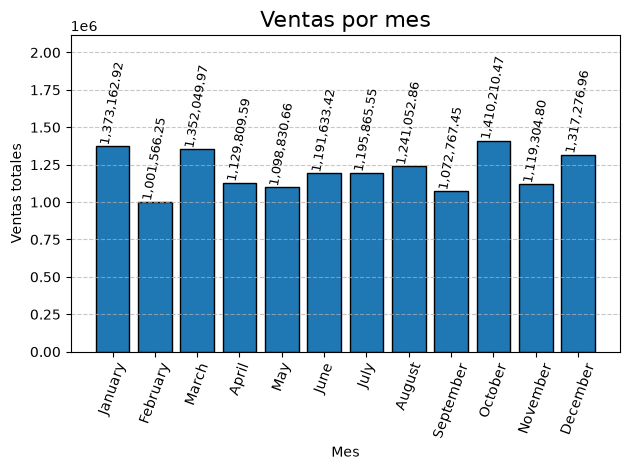

In [62]:
ventas_mes = (
    ventas_limpias
    .groupby(["mes", "mes_nombre"], as_index=False)["total_venta"]
    .sum()
    .sort_values(["mes"])
)


barras = plt.bar(
     ventas_mes["mes_nombre"],
     ventas_mes["total_venta"],
edgecolor = "black"
)


for barra,importe in zip(barras,ventas_mes["total_venta"]):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 300,
        f"{importe:,.2f}",
        ha="center",
        va ="bottom",
        fontsize = 9,
        rotation=80
    )

plt.title("Ventas por mes",fontsize=16)
plt.xlabel("Mes")
plt.ylabel("Ventas totales")

plt.xticks(rotation=70)
plt.ylim(0,max(ventas_mes["total_venta"])*1.50)
plt.grid(axis="y",linestyle="--",alpha=0.7)
plt.tight_layout()
plt.show()

### 2. Grafico de pastel.

En este diagram podemos obser un top 10 de productos que mas se han vendido.

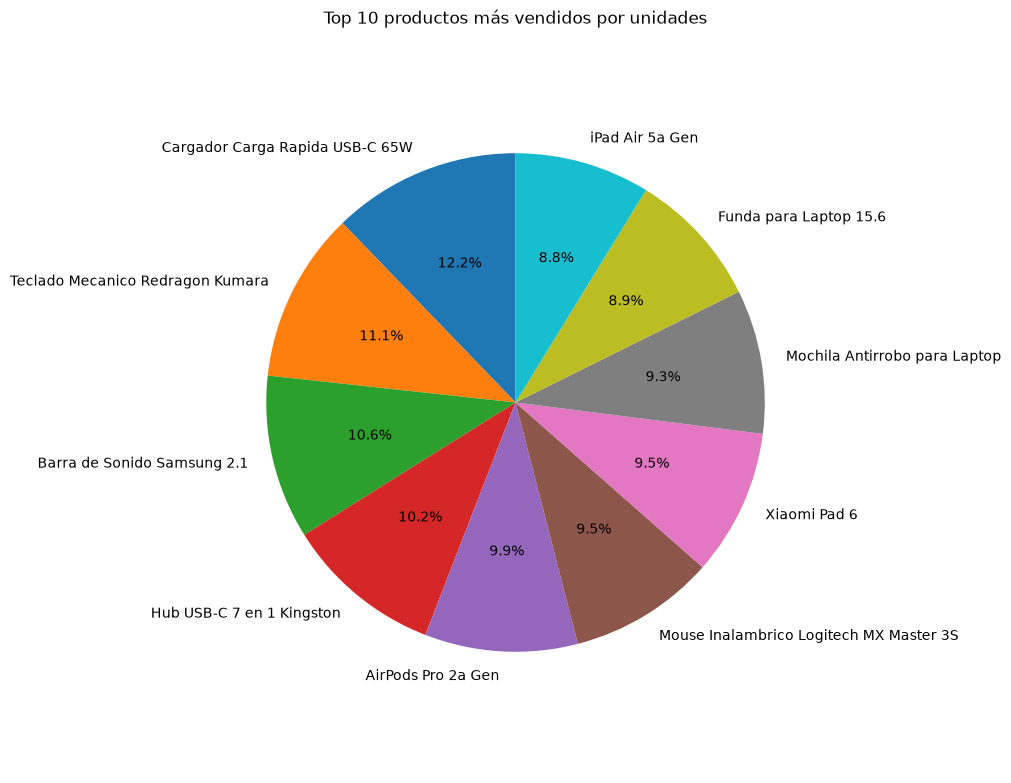

In [63]:
ventas_producto = (
    ventas_limpias
    .groupby("producto")["cantidad"]
    .sum()
    .sort_values(ascending=False)
)

top_10 = ventas_producto.head(10)

plt.figure(figsize=(10, 8))

plt.pie(
    top_10.values,
    labels=top_10.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 10 productos más vendidos por unidades")
plt.axis("equal")
plt.tight_layout()
plt.show()

### 3. Grafico de barras horizontales.
En este podemos observar las venta o importes por categoria siendo la que mas ventas o importes nos genera las laptos y la que menos nos generan los accesorios.

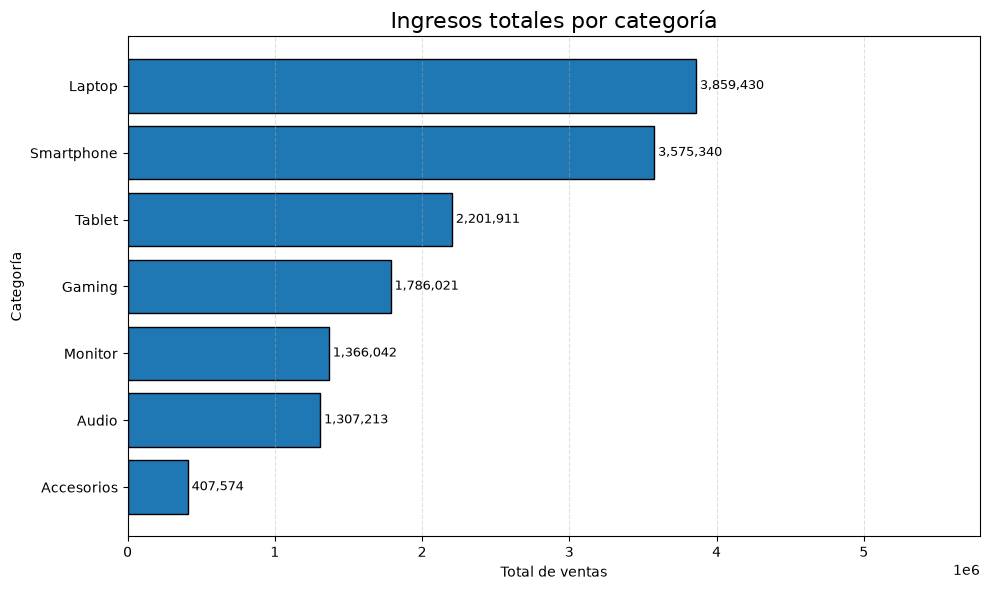

In [64]:
ventas_categoria = (
    ventas_limpias
    .groupby("categoria")["total_venta"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    ventas_categoria.index,
    ventas_categoria.values,
    edgecolor="black"
)


for barra in barras:
    valor = barra.get_width()

    plt.text(
        valor,
        barra.get_y() + barra.get_height() / 2,
        f" {valor:,.0f}",
        va="center",
        fontsize=9
    )

plt.title("Ingresos totales por categoría", fontsize=16)
plt.xlabel("Total de ventas")
plt.ylabel("Categoría")

plt.xlim(0,max(ventas_categoria.values)*1.50)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 4. Grafico de dispersión.

* **Lo que más se vende:** La gran mayoría de los clientes compra solo 1 o 2 productos a la vez.

* **La venta más cara:** Las compras que más dinero dejaron llegan cerca de 60,000 fueron de 2 productos, los cuales podrian ser uno de los productos mas caros.

* **Muchos productos, poco dinero:** Cuando la gente se lleva 4 o 5 productos, el total de la venta es muy bajo menos de 10,000. Esto significa que esos artículos son muy baratos.

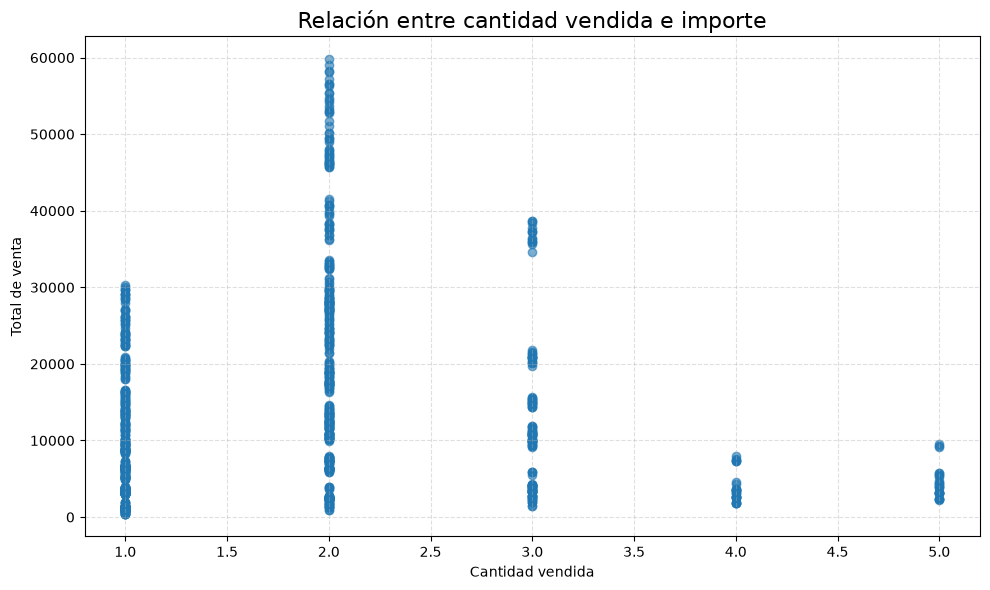

In [65]:
plt.figure(figsize=(10, 6))

plt.scatter(
    ventas_limpias["cantidad"],
    ventas_limpias["total_venta"],
    alpha=0.6
)

plt.title("Relación entre cantidad vendida e importe", fontsize=16)
plt.xlabel("Cantidad vendida")
plt.ylabel("Total de venta")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 5. Grafico de caja.
* **Montos muy similares:** La distribución del dinero es bastante parecida en los cuatro métodos. Las cajas empiezan y terminan casi en los mismos niveles.

* **Transferencia se usa para compras más grandes:** La caja de "Transferencia" está un poco más arriba que las demás, lo que indica que cuando la gente transfiere, suele gastar un poco más en promedio.

* **Efectivo se usa para compras más pequeñas:** La mediana de "Efectivo" es la más baja de todas.

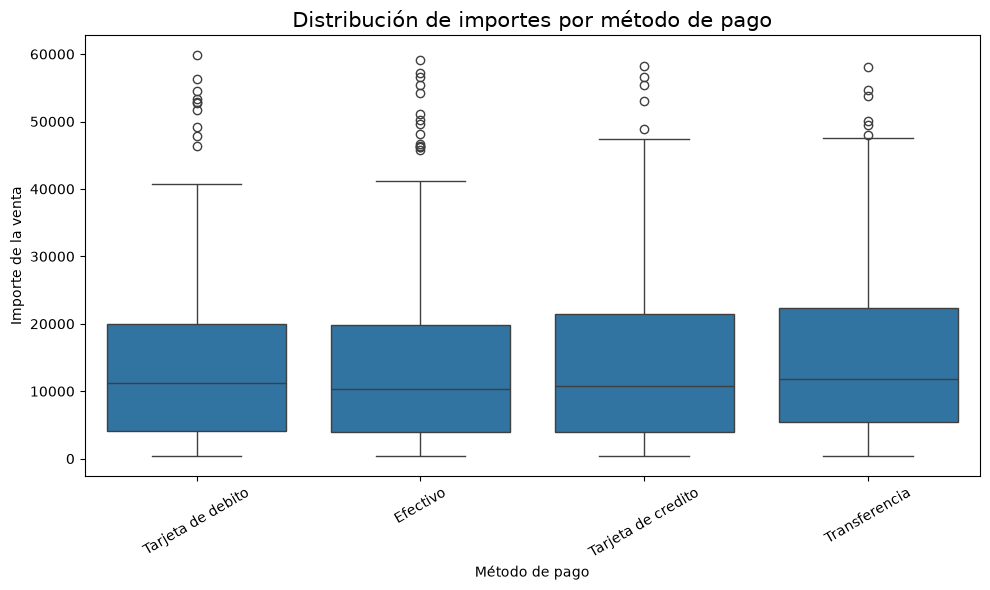

In [66]:
plt.figure(figsize=(10, 6))

sbs.boxplot(
    data=ventas_limpias,
    x="metodo_pago",
    y="total_venta",
    showfliers=True
)

plt.title("Distribución de importes por método de pago", fontsize=15)
plt.xlabel("Método de pago")
plt.ylabel("Importe de la venta")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 6. Gráfica de dispersión con burbujas y escala de colores.

* **El producto mas vendido (punto amarillo):** Con solo 51 unidades vendidas, se consiguió el importe más alto de todos. Es el producto que más ganancias deja.

* **Mucho volumen, poco dinero (puntos morados abajo a la derecha):** Aunque de estos productos se vendieron muchas piezas (más de 60), dejaron muy poco dinero. Significa que son cosas muy baratas.

* **El punto medio estable (puntos verdes):** Vender entre 30 y 40 unidades de productos con precio medio es lo que mantiene el negocio funcionando de forma estable.


In [67]:
import plotly.express as px

ventas_producto = (
    ventas_limpias
    .groupby("producto", as_index=False)
    .agg(
        total_venta=("total_venta", "sum"),
        unidades=("cantidad", "sum")
    )
    .sort_values("total_venta", ascending=False)
    .head(15)
)


fig = px.scatter(
    ventas_producto,
    x="unidades",
    y="total_venta",
    size="total_venta",
    color="total_venta",
    hover_name="producto",
    hover_data={
        "unidades": True,
        "total_venta": ":,.2f"
    },
    title="Exploración interactiva: productos y ventas",
    labels={
        "unidades": "Unidades vendidas",
        "total_venta": "Ingresos totales"
    },
    template="plotly_white",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    width=1000,
    height=600
)

fig.show()